# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Виконав:** Брагнюк Андрій Романович  
**Група:** 4-8  
**Дата:** 23.11.2026

**Мета:** навчити нейронну мережу розпізнавати одяг на зображеннях Fashion MNIST
та порівняти її з моделлю після добору гіперпараметрів.

## Підготовка

Підключаю бібліотеки. Фіксую seed, щоб зменшити відмінності між повторними запусками.
Комірки виконуються зверху вниз. Для повторного запуску в Google Colab потрібен інтернет.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix

keras.utils.set_random_seed(42)
plt.rcParams['figure.dpi'] = 100

print('TensorFlow:', tf.__version__)
print('Keras:', keras.__version__)

TensorFlow: 2.21.0
Keras: 3.15.1


# Завдання 1. Класифікація Fashion MNIST

### 1. Завантаження даних

Завантажую зображення розміром 28 × 28 пікселів. Числовим міткам 0–9 задаю назви класів.

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.fashion_mnist.load_data()

class_names = [
    'Футболка', 'Штани', 'Светр', 'Сукня', 'Пальто',
    'Сандалі', 'Сорочка', 'Кросівки', 'Сумка', 'Черевики'
]

print('x_train:', x_train.shape, 'y_train:', y_train.shape)
print('x_test: ', x_test.shape, 'y_test: ', y_test.shape)

x_train: (60000, 28, 28) y_train: (60000,)
x_test:  (10000, 28, 28) y_test:  (10000,)


### 2. Перегляд зображень

Виводжу перші 10 навчальних зображень із назвами класів.

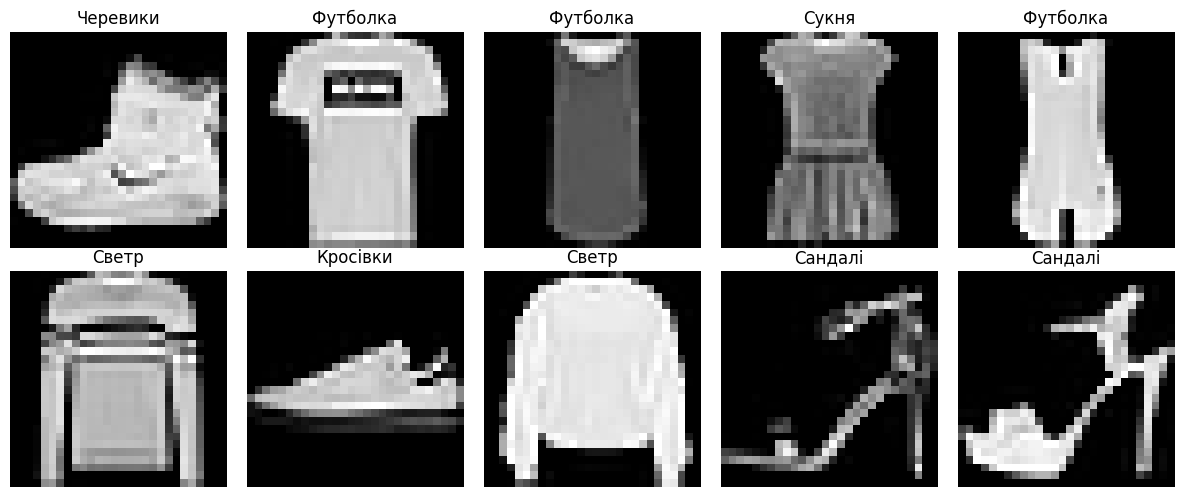

In [3]:
plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

### 3. Нормалізація та поділ даних

Ділю значення пікселів на 255 та використовую тип float32.
Із 60 000 навчальних прикладів виділяю 20% для валідації зі збереженням часток класів.
Тестові дані залишаю для оцінювання готових моделей.

In [4]:
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

x_fit, x_val, y_fit, y_val = train_test_split(
    x_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

print('Тип даних:', x_train.dtype)
print('Діапазон навчальних даних:', x_train.min(), x_train.max())
print('Діапазон тестових даних:', x_test.min(), x_test.max())
print('Навчання:', x_fit.shape)
print('Валідація:', x_val.shape)
print('Тестування:', x_test.shape)

Тип даних: float32
Діапазон навчальних даних: 0.0 1.0
Діапазон тестових даних: 0.0 1.0
Навчання: (48000, 28, 28)
Валідація: (12000, 28, 28)
Тестування: (10000, 28, 28)


### 4. Побудова моделі

Беру два приховані шари: 256 і 128 нейронів. Перший виділяє ознаки, другий узагальнює їх.
Dropout 0,2 зменшує перенавчання. Для Adam задаю початковий крок 0,001.
На виході — 10 імовірностей класів. Оскільки мітки цілочисельні, використовую sparse categorical crossentropy.

In [5]:
model = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(10, activation='softmax')
], name='fashion_basic')

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

### 5. Навчання

Навчаю до 30 епох пакетами по 128 зображень. Якщо val_loss не зменшується,
знижую крок навчання, а після п'яти епох без покращення зупиняю навчання.
Відновлюю ваги з найменшими валідаційними втратами.

In [6]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001)
]

history = model.fit(
    x_fit, y_fit,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=callbacks,
    verbose=2
)

Epoch 1/30
375/375 - 2s - 7ms/step - accuracy: 0.7819 - loss: 0.6165 - val_accuracy: 0.8383 - val_loss: 0.4257 - learning_rate: 0.0010
Epoch 2/30
375/375 - 1s - 4ms/step - accuracy: 0.8445 - loss: 0.4237 - val_accuracy: 0.8658 - val_loss: 0.3650 - learning_rate: 0.0010
Epoch 3/30
375/375 - 1s - 4ms/step - accuracy: 0.8603 - loss: 0.3802 - val_accuracy: 0.8712 - val_loss: 0.3480 - learning_rate: 0.0010
Epoch 4/30
375/375 - 3s - 8ms/step - accuracy: 0.8690 - loss: 0.3536 - val_accuracy: 0.8801 - val_loss: 0.3292 - learning_rate: 0.0010
Epoch 5/30
375/375 - 1s - 4ms/step - accuracy: 0.8767 - loss: 0.3364 - val_accuracy: 0.8843 - val_loss: 0.3193 - learning_rate: 0.0010
Epoch 6/30
375/375 - 1s - 4ms/step - accuracy: 0.8810 - loss: 0.3217 - val_accuracy: 0.8857 - val_loss: 0.3170 - learning_rate: 0.0010
Epoch 7/30
375/375 - 2s - 4ms/step - accuracy: 0.8842 - loss: 0.3126 - val_accuracy: 0.8873 - val_loss: 0.3123 - learning_rate: 0.0010
Epoch 8/30
375/375 - 2s - 5ms/step - accuracy: 0.8893 -

### 6. Структура мережі

Перевіряю шари та кількість параметрів. У model.layers вхідний Input не враховується.
model.count_params() показує параметри мережі без стану оптимізатора.

In [7]:
model.summary()
print('Кількість шарів без Input:', len(model.layers))
print('Прихованих Dense-шарів:', 2)
print('Параметрів мережі:', model.count_params())

Model: "fashion_basic"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼──────────────────

### 7. Збереження моделі

Зберігаю навчену модель у поточній папці у форматі .keras.
У Colab цей файл можна завантажити з панелі «Файли».

In [8]:
model.save('fashion_mnist_basic.keras')
print('Збережено fashion_mnist_basic.keras')

Збережено fashion_mnist_basic.keras


### 8. Графіки навчання

Порівнюю втрати та точність на навчальній і валідаційній вибірках.

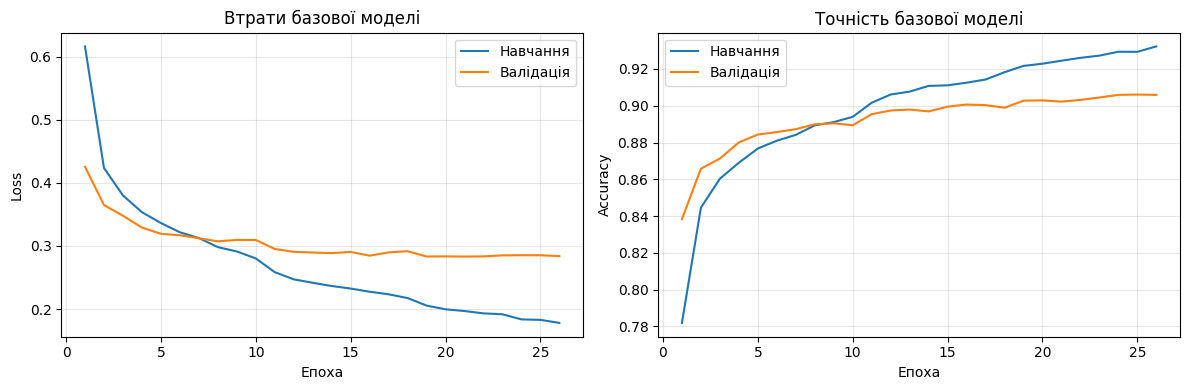

In [9]:
epochs = range(1, len(history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, history.history['loss'], label='Навчання')
axes[0].plot(epochs, history.history['val_loss'], label='Валідація')
axes[0].set(title='Втрати базової моделі', xlabel='Епоха', ylabel='Loss')

axes[1].plot(epochs, history.history['accuracy'], label='Навчання')
axes[1].plot(epochs, history.history['val_accuracy'], label='Валідація')
axes[1].set(title='Точність базової моделі', xlabel='Епоха', ylabel='Accuracy')

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 9. Оцінювання на тестових даних

Оцінюю готову модель та формую звіт для всіх класів.
Після перегляду тестових результатів параметри моделі не змінюю.

In [10]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
probabilities = model.predict(x_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4f}')
print('Умову accuracy >= 0.87 виконано:', test_accuracy >= 0.87)
print()
print(classification_report(
    y_test, y_pred, target_names=class_names, digits=3, zero_division=0
))

Test loss: 0.3207
Test accuracy: 0.8910
Умову accuracy >= 0.87 виконано: True

              precision    recall  f1-score   support

    Футболка      0.835     0.859     0.847      1000
       Штани      0.985     0.978     0.981      1000
       Светр      0.774     0.833     0.803      1000
       Сукня      0.906     0.886     0.896      1000
      Пальто      0.809     0.818     0.814      1000
     Сандалі      0.982     0.966     0.974      1000
     Сорочка      0.737     0.677     0.706      1000
    Кросівки      0.949     0.963     0.956      1000
       Сумка      0.977     0.967     0.972      1000
    Черевики      0.958     0.963     0.961      1000

    accuracy                          0.891     10000
   macro avg      0.891     0.891     0.891     10000
weighted avg      0.891     0.891     0.891     10000



In [11]:
# Знаходжу класи з найбільшою кількістю помилок.
cm = confusion_matrix(y_test, y_pred)
class_errors = cm.sum(axis=1) - np.diag(cm)

errors_table = pd.DataFrame({
    'Клас': class_names,
    'Помилок': class_errors,
    'Зображень': cm.sum(axis=1)
}).sort_values('Помилок', ascending=False)

errors_table.head(3)

,Клас,Помилок,Зображень
6,Сорочка,323,1000
4,Пальто,182,1000
2,Светр,167,1000


### 10. Приклади прогнозів

Зелений підпис означає правильний прогноз, червоний — помилку.

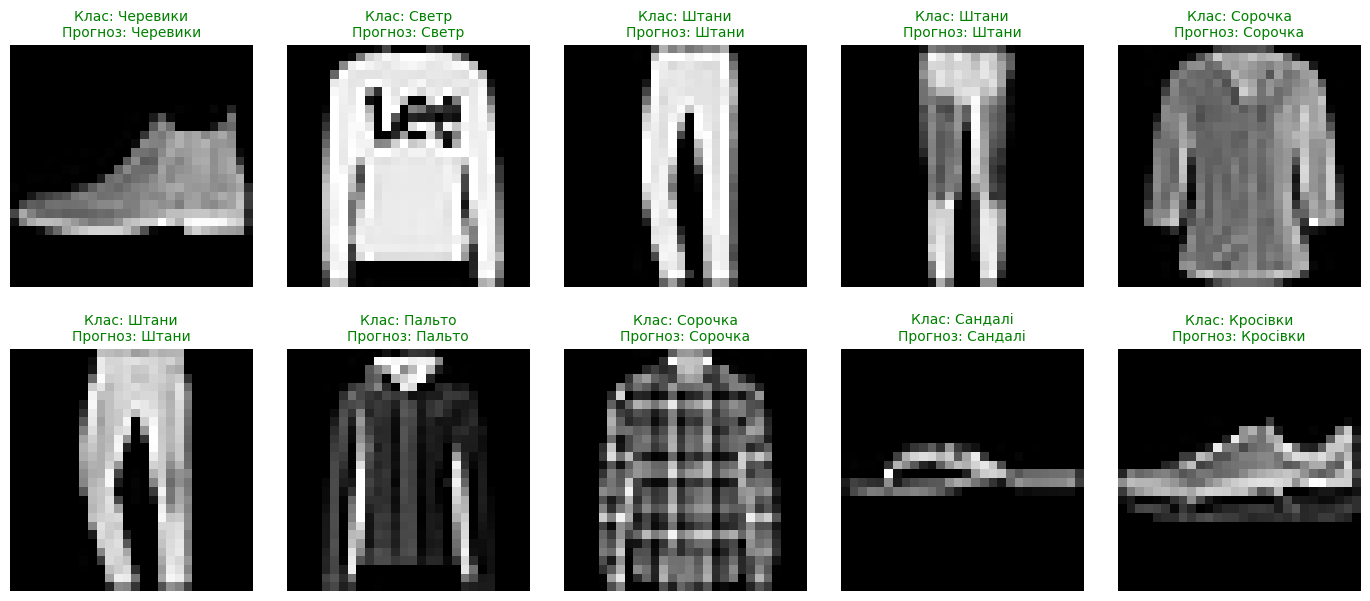

In [12]:
plt.figure(figsize=(14, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray')
    color = 'green' if y_test[i] == y_pred[i] else 'red'
    plt.title(
        f'Клас: {class_names[y_test[i]]}\nПрогноз: {class_names[y_pred[i]]}',
        color=color, fontsize=10
    )
    plt.axis('off')

plt.tight_layout(h_pad=3.5)
plt.show()

**Проміжний висновок.** Тестова точність становить 0,8910 (89,10%). Вимогу accuracy ≥ 0,87 виконано. Найбільше помилок за класами: «Сорочка» — 323, «Пальто» — 182, «Светр» — 167 із 1000 зображень кожного класу. Найчастіша окрема плутанина: «Сорочка» → «Футболка» (125 випадків).

# Завдання 2. Добір гіперпараметрів

### 1. Підготовка Keras Tuner

Встановлюю бібліотеку та підключаю RandomSearch і L2-регуляризацію.

In [13]:
%pip install -q keras-tuner tensorboard


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [14]:
import keras_tuner as kt
from keras_tuner import RandomSearch
from tensorflow.keras.layers import Dense, Flatten, Dropout
from tensorflow.keras.regularizers import l2

print('Keras Tuner:', kt.__version__)

Keras Tuner: 1.4.8


### 2. Дані для пошуку

Використовую той самий поділ: 48 000 прикладів для навчання та 12 000 для валідації.
Тестові 10 000 зображень у пошуку не беруть участі.

In [15]:
print('Навчальна вибірка:', x_fit.shape, y_fit.shape)
print('Валідаційна вибірка:', x_val.shape, y_val.shape)
print('Тестова вибірка:', x_test.shape, y_test.shape)
print('Діапазон для навчання:', x_fit.min(), x_fit.max())

Навчальна вибірка: (48000, 28, 28) (48000,)
Валідаційна вибірка: (12000, 28, 28) (12000,)
Тестова вибірка: (10000, 28, 28) (10000,)
Діапазон для навчання: 0.0 1.0


### 3. Функція побудови моделі

Перевіряю від 1 до 3 прихованих шарів, від 32 до 512 нейронів із кроком 32
та крок навчання 0,01; 0,001; 0,0001. У межах однієї моделі всі приховані шари
мають однакову кількість нейронів. Dropout 0,2 та L2 0,0001 залишаю фіксованими.

In [16]:
def build_model(hp):
    num_layers = hp.Int('num_layers', min_value=1, max_value=3)
    units = hp.Int('units', min_value=32, max_value=512, step=32)
    learning_rate = hp.Choice('learning_rate', values=[0.01, 0.001, 0.0001])

    tuned_model = keras.Sequential([keras.Input(shape=(28, 28)), Flatten()])

    for i in range(num_layers):
        tuned_model.add(Dense(units, activation='relu', kernel_regularizer=l2(0.0001)))
        tuned_model.add(Dropout(0.2))

    tuned_model.add(Dense(10, activation='softmax'))
    tuned_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return tuned_model

### 4. Налаштування пошуку

Задаю три випадкові конфігурації та одне навчання кожної.
Найкращу конфігурацію вибираю за val_accuracy. Результати зберігаються в папці tuner_results.

In [17]:
keras.utils.set_random_seed(42)
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='tuner_results',
    project_name='fashion_mnist_lab10',
    overwrite=True,
    seed=42
)

tuner.search_space_summary()

Search space summary
Default search space size: 3
num_layers (Int)
{'default': None, 'conditions': [], 'min_value': 1, 'max_value': 3, 'step': 1, 'sampling': 'linear'}
units (Int)
{'default': None, 'conditions': [], 'min_value': 32, 'max_value': 512, 'step': 32, 'sampling': 'linear'}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 0.0001], 'ordered': True}


### 5. Пошук і навчання вибраної моделі

На кожну спробу виділяю до 20 епох. Рання зупинка та зменшення кроку навчання
орієнтуються на валідаційні втрати.

In [18]:
tuner.search(
    x_fit, y_fit,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001)
    ],
    verbose=2
)


Search: Running Trial #1

Value             |Best Value So Far |Hyperparameter
2                 |2                 |num_layers
32                |32                |units
0.001             |0.001             |learning_rate

Epoch 1/20
375/375 - 2s - 5ms/step - accuracy: 0.6477 - loss: 1.0027 - val_accuracy: 0.8092 - val_loss: 0.5335 - learning_rate: 0.0010
Epoch 2/20
375/375 - 1s - 2ms/step - accuracy: 0.7799 - loss: 0.6299 - val_accuracy: 0.8372 - val_loss: 0.4578 - learning_rate: 0.0010
Epoch 3/20
375/375 - 1s - 3ms/step - accuracy: 0.8059 - loss: 0.5615 - val_accuracy: 0.8462 - val_loss: 0.4303 - learning_rate: 0.0010
Epoch 4/20
375/375 - 1s - 2ms/step - accuracy: 0.8176 - loss: 0.5272 - val_accuracy: 0.8577 - val_loss: 0.4114 - learning_rate: 0.0010
Epoch 5/20
375/375 - 1s - 2ms/step - accuracy: 0.8258 - loss: 0.5047 - val_accuracy: 0.8568 - val_loss: 0.4076 - learning_rate: 0.0010
Epoch 6/20
375/375 - 2s - 4ms/step - accuracy: 0.8301 - loss: 0.4924 - val_accuracy: 0.8638 - val_l

In [19]:
# Порівнюю три спроби за валідаційною точністю.
trial_rows = []
for trial in tuner.oracle.trials.values():
    hp = trial.hyperparameters
    trial_rows.append({
        'Спроба': int(trial.trial_id) + 1,
        'Шарів': hp.get('num_layers'),
        'Нейронів у шарі': hp.get('units'),
        'Початковий крок': hp.get('learning_rate'),
        'Найкраща val_accuracy': trial.score
    })

trials_table = pd.DataFrame(trial_rows).sort_values('Спроба')
trials_table

,Спроба,Шарів,Нейронів у шарі,Початковий крок,Найкраща val_accuracy
0,1,2,32,0.001,0.876083
1,2,1,480,0.001,0.902333
2,3,2,64,0.001,0.889500


In [20]:
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print('Прихованих шарів:', best_hp.get('num_layers'))
print('Нейронів у кожному шарі:', best_hp.get('units'))
print('Початкова швидкість навчання:', best_hp.get('learning_rate'))

# Навчаю вибрану конфігурацію заново та зберігаю історію.
keras.utils.set_random_seed(42)
best_model = tuner.hypermodel.build(best_hp)
best_model.summary()

history_best = best_model.fit(
    x_fit, y_fit,
    validation_data=(x_val, y_val),
    epochs=30,
    batch_size=128,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=0.00001)
    ],
    verbose=2
)

Прихованих шарів: 1
Нейронів у кожному шарі: 480
Початкова швидкість навчання: 0.001
Model: "sequential_1"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 480)            │       376,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 480)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         4,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘
 Total params: 381,610 (1.46 MB)
 Trainable pa

### 6. Фінальне оцінювання та графіки

Оцінюю повторно навчену модель на тестових даних та зберігаю її.
У цієї моделі loss включає штраф L2, тому втрати двох моделей не цілком зіставні.
Основною метрикою порівняння беру accuracy.

In [21]:
best_loss, best_accuracy = best_model.evaluate(x_test, y_test, verbose=0)
print(f'Test loss після добору: {best_loss:.4f}')
print(f'Test accuracy після добору: {best_accuracy:.4f}')

best_model.save('fashion_mnist_tuned.keras')
print('Збережено fashion_mnist_tuned.keras')

Test loss після добору: 0.3522
Test accuracy після добору: 0.8934
Збережено fashion_mnist_tuned.keras


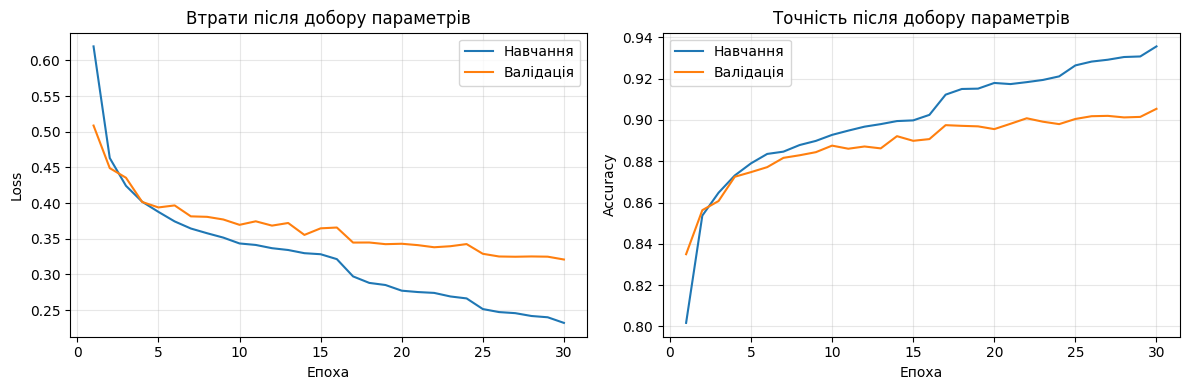

In [22]:
epochs_best = range(1, len(history_best.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs_best, history_best.history['loss'], label='Навчання')
axes[0].plot(epochs_best, history_best.history['val_loss'], label='Валідація')
axes[0].set(title='Втрати після добору параметрів', xlabel='Епоха', ylabel='Loss')

axes[1].plot(epochs_best, history_best.history['accuracy'], label='Навчання')
axes[1].plot(epochs_best, history_best.history['val_accuracy'], label='Валідація')
axes[1].set(title='Точність після добору параметрів', xlabel='Епоха', ylabel='Accuracy')

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Порівняння моделей

Кількість епох показує фактично виконане навчання. Для моделі після пошуку
вказую епохи її повторного навчання, без трьох пошукових спроб.
Крок навчання в таблиці — початковий, до зменшення callback-функцією.

In [23]:
comparison = pd.DataFrame({
    'Показник': [
        'Прихованих шарів', 'Нейронів у прихованих шарах',
        'Початкова швидкість навчання', 'Тестова accuracy',
        'Тестові втрати', 'Виконано епох', 'Найкраща епоха за val_loss'
    ],
    'Базова модель': [
        2, '256, 128', 0.001, round(test_accuracy, 4), round(test_loss, 4),
        len(history.history['loss']), int(np.argmin(history.history['val_loss'])) + 1
    ],
    'Після Keras Tuner': [
        best_hp.get('num_layers'),
        ', '.join([str(best_hp.get('units'))] * best_hp.get('num_layers')),
        best_hp.get('learning_rate'), round(best_accuracy, 4), round(best_loss, 4),
        len(history_best.history['loss']), int(np.argmin(history_best.history['val_loss'])) + 1
    ]
})

comparison

,Показник,Базова модель,Після Keras Tuner
0,Прихованих шарів,2,1
1,Нейронів у прихованих шарах,"256, 128",480
2,Початкова швидкість навчання,0.001,0.001
3,Тестова accuracy,0.891,0.8934
4,Тестові втрати,0.3207,0.3522
5,Виконано епох,26,30
6,Найкраща епоха за val_loss,21,30


## Висновки

1. Базова модель отримала accuracy 0,8910 і loss 0,3207. Вимогу мінімальної точності 0,87 виконано.
2. Після Keras Tuner тестова accuracy становить 0,8934, loss — 0,3522. Точність зросла на 0,24 відсоткового пункту.
3. Найкраща за val_accuracy з трьох перевірених конфігурацій: прихованих шарів — 1, нейронів у кожному — 480, початковий крок навчання — 0,001. Три спроби не охоплюють усі комбінації. На результат також впливають початкові ваги, перемішування даних, Dropout і середовище виконання; seed зменшує випадковість, але не гарантує однакового результату на різному обладнанні.
4. Найскладнішими для базової моделі виявилися класи «Сорочка», «Пальто», «Светр». Кількість помилок наведено в таблиці після класифікаційного звіту.

## Використані матеріали

- [TensorFlow: класифікація Fashion MNIST](https://www.tensorflow.org/tutorials/keras/classification).
- [Keras Tuner: RandomSearch](https://keras.io/api/keras_tuner/tuners/random/).